# Transfer learning

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://githubtocolab.com/EnriqueVilchezL/machine-learning/blob/main/book/06-deep-learning/transfer-learning/transfer-learning-notebook.ipynb)

Companion notebook for the *Transfer learning* slides. Each idea is written first by hand
with NumPy and then with the PyTorch tools that do the same job.

**Data:** the handwritten Digits (1797 images of 8x8 pixels). The source task is naming the digit
(0 to 9) on one half of the images; the target task, on the other half, is telling whether a digit has a closed loop (0, 6, 8, 9).

In [1]:
import copy

import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from torch import nn

RANDOM_STATE = 42
HIDDEN = 64
EPOCHS = 300
FEW_PER_CLASS = 5
N_T_CHOICES = [3, 5, 10, 25, 50]
DRAWS = 5
FT_LEARNING_RATE = 0.1
HEAD_LEARNING_RATE = 0.5
FT_EPOCHS = 300

torch.manual_seed(RANDOM_STATE)
torch.set_default_dtype(torch.float64)

X, y = load_digits(return_X_y=True)
X = X / 16
X_source, X_target, y_source, digit_target = train_test_split(
    X, y, test_size=0.5, random_state=RANDOM_STATE, stratify=y)
y_target = np.isin(digit_target, [0, 6, 8, 9]).astype(int)
XT_train, XT_test, yT_train, yT_test = train_test_split(
    X_target, y_target, test_size=0.5, random_state=RANDOM_STATE, stratify=y_target)
X_source_t = torch.tensor(X_source)
y_source_t = torch.tensor(y_source)
XT_train_t = torch.tensor(XT_train)
yT_train_t = torch.tensor(yT_train)
XT_test_t = torch.tensor(XT_test)
yT_test_t = torch.tensor(yT_test)


def few_labels(per_class: int, seed: int) -> np.ndarray:
    """Indices of `per_class` random target training examples of each class."""
    rng = np.random.default_rng(seed)
    chosen = []
    for c in (0, 1):
        rows_of_class = np.flatnonzero(yT_train == c)
        chosen.append(rng.choice(rows_of_class, per_class, replace=False))
    return np.concatenate(chosen)


def softmax(scores: np.ndarray) -> np.ndarray:
    """Softmax on each row."""
    e = np.exp(scores - scores.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)

## 1. Pretraining on the source task

A network with one hidden layer learns $\boldsymbol\theta_S$ on the many source images. Its forward pass is
$\hat{\mathbf{y}} = \text{softmax}\big(\mathbf{W}^{(2)} g(\mathbf{W}^{(1)}\mathbf{x} + \mathbf{b}^{(1)}) + \mathbf{b}^{(2)}\big)$ with $g$ = ReLU.
By hand, three tiny NumPy classes copy the shape of `nn.Linear`, `nn.ReLU` and `nn.Sequential`.

In [2]:
class Linear:
    """NumPy twin of nn.Linear: weight is (out, in), output x W^T + b."""
    def __init__(self, in_features: int, out_features: int):
        self.weight = np.zeros((out_features, in_features))
        self.bias = np.zeros(out_features)

    def __call__(self, x: np.ndarray) -> np.ndarray:
        return x @ self.weight.T + self.bias


class ReLU:
    """NumPy twin of nn.ReLU."""
    def __call__(self, x: np.ndarray) -> np.ndarray:
        return np.maximum(x, 0)


class Sequential:
    """NumPy twin of nn.Sequential: apply the layers in order."""
    def __init__(self, *layers):
        self.layers = list(layers)

    def __call__(self, x: np.ndarray) -> np.ndarray:
        for layer in self.layers:
            x = layer(x)
        return x


def copy_weights(mine: Sequential, theirs: nn.Sequential) -> None:
    """Copy the weights of a torch network into its NumPy twin."""
    for layer, torch_layer in zip(mine.layers, theirs):
        if isinstance(layer, Linear):
            layer.weight = torch_layer.weight.detach().numpy().copy()
            layer.bias = torch_layer.bias.detach().numpy().copy()

In PyTorch the same network is `nn.Sequential`, trained with `nn.CrossEntropyLoss` (softmax and cross-entropy in one)
and an optimizer. The loop is the one of the slides: forward pass, loss, backpropagation, update.

In [3]:
def fit(model: nn.Module, inputs: torch.Tensor, labels: torch.Tensor, epochs: int = EPOCHS) -> nn.Module:
    """Full-batch Adam on the parameters that require gradients."""
    trainable = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.Adam(trainable, lr=0.01)
    for _ in range(epochs):
        optimizer.zero_grad()
        scores = model(inputs)
        loss = nn.functional.cross_entropy(scores, labels)
        loss.backward()
        optimizer.step()
    return model


def accuracy(model: nn.Module, inputs: torch.Tensor, labels: torch.Tensor) -> float:
    """Share of correct predictions."""
    with torch.no_grad():
        predictions = model(inputs).argmax(dim=1)
        correct = (predictions == labels).double()
        return correct.mean().item()


source_net = nn.Sequential(nn.Linear(64, HIDDEN), nn.ReLU(), nn.Linear(HIDDEN, 10))
fit(source_net, X_source_t, y_source_t)

numpy_net = Sequential(Linear(64, HIDDEN), ReLU(), Linear(HIDDEN, 10))
copy_weights(numpy_net, source_net)
proba_by_hand = softmax(numpy_net(X_target))
proba_torch = torch.softmax(source_net(torch.tensor(X_target)), dim=1)
print("same result:", np.allclose(proba_by_hand, proba_torch.detach().numpy()))

same result: True


## 2. Feature extraction: frozen body, new head

The frozen body gives the features $\boldsymbol\phi(\mathbf{x}) = g(\mathbf{W}^{(1)}\mathbf{x} + \mathbf{b}^{(1)})$.
In PyTorch the body is the first two layers, `requires_grad_(False)` freezes it, and a new `nn.Linear` head
with two outputs, $\hat{\mathbf{y}} = \text{softmax}(\mathbf{W}_{\text{head}}\boldsymbol\phi(\mathbf{x}) + \mathbf{b}_{\text{head}})$, is trained on few target labels.

In [4]:
body = source_net[:2].requires_grad_(False)
rows = few_labels(FEW_PER_CLASS, RANDOM_STATE)
transfer_net = nn.Sequential(body, nn.Linear(HIDDEN, 2))
fit(transfer_net, XT_train_t[rows], yT_train_t[rows])

phi = Sequential(*numpy_net.layers[:2])
head = Linear(HIDDEN, 2)
head.weight = transfer_net[1].weight.detach().numpy()
head.bias = transfer_net[1].bias.detach().numpy()
features = phi(XT_test)  # phi(x)
p_by_hand = softmax(head(features))  # softmax(W_head phi(x) + b_head)
p_torch = torch.softmax(transfer_net(XT_test_t), dim=1).detach().numpy()
print("same result:", np.allclose(p_by_hand, p_torch))
print("body unchanged:", np.array_equal(numpy_net.layers[0].weight, body[0].weight.numpy()))
n_trainable = sum(p.numel() for p in transfer_net.parameters() if p.requires_grad)
n_frozen = sum(p.numel() for p in body.parameters())
print("trainable parameters:", n_trainable, "| frozen:", n_frozen)

same result: True
body unchanged: True
trainable parameters: 130 | frozen: 4160


Always compare with the same network trained from scratch on the same few labels.

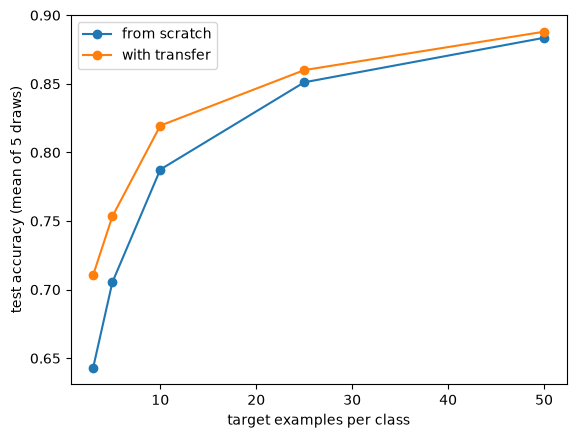

In [5]:
results = {"from scratch": [], "with transfer": []}
for n_T in N_T_CHOICES:
    scratch, transfer = [], []
    for seed in range(DRAWS):
        rows = few_labels(n_T, seed)
        scratch_net = nn.Sequential(nn.Linear(64, HIDDEN), nn.ReLU(), nn.Linear(HIDDEN, 2))
        fit(scratch_net, XT_train_t[rows], yT_train_t[rows])
        scratch.append(accuracy(scratch_net, XT_test_t, yT_test_t))
        new_net = nn.Sequential(body, nn.Linear(HIDDEN, 2))
        fit(new_net, XT_train_t[rows], yT_train_t[rows])
        transfer.append(accuracy(new_net, XT_test_t, yT_test_t))
    results["from scratch"].append(np.mean(scratch))
    results["with transfer"].append(np.mean(transfer))

for label, values in results.items():
    plt.plot(N_T_CHOICES, values, marker="o", label=label)
plt.xlabel("target examples per class")
plt.ylabel(f"test accuracy (mean of {DRAWS} draws)")
plt.legend()
plt.show()

## 3. Fine-tuning

Fine-tuning also trains the body, starting at the source parameters, $\boldsymbol\theta^{(0)} = \boldsymbol\theta_S$,
with a small step: $\boldsymbol\theta \leftarrow \boldsymbol\theta - \alpha_{\text{ft}} \nabla J_T(\boldsymbol\theta)$.
It needs more labels than a head alone, so here we use all the target training images. We first train a head on the
frozen body, then copy the whole network with `copy.deepcopy` and unfreeze it with `requires_grad_(True)`.
Two parameter groups give the body a small rate $\alpha_{\text{ft}}$ and the head a larger one.

In [6]:
frozen_net = nn.Sequential(copy.deepcopy(body), nn.Linear(HIDDEN, 2))
fit(frozen_net, XT_train_t, yT_train_t)
tuned = copy.deepcopy(frozen_net).requires_grad_(True)
body_group = {"params": tuned[0].parameters(), "lr": FT_LEARNING_RATE}
head_group = {"params": tuned[1].parameters(), "lr": HEAD_LEARNING_RATE}
optimizer = torch.optim.SGD([body_group, head_group])
loss_fn = nn.CrossEntropyLoss()

W1_before = tuned[0][0].weight.detach().clone()
optimizer.zero_grad()
loss = loss_fn(tuned(XT_train_t), yT_train_t)
loss.backward()
grad_W1 = tuned[0][0].weight.grad  # gradient of J_T for W^(1)
W1_by_hand = W1_before - FT_LEARNING_RATE * grad_W1  # theta - alpha_ft * grad
optimizer.step()
print("same result:", torch.allclose(W1_by_hand, tuned[0][0].weight))

same result: True


In [7]:
accuracy_before = accuracy(frozen_net, XT_test_t, yT_test_t)
print(f"before fine-tuning: test accuracy {accuracy_before:.3f}")
for _ in range(FT_EPOCHS - 1):
    optimizer.zero_grad()
    scores = tuned(XT_train_t)
    loss = loss_fn(scores, yT_train_t)
    loss.backward()
    optimizer.step()
accuracy_after = accuracy(tuned, XT_test_t, yT_test_t)
print(f"after {FT_EPOCHS} epochs: test accuracy {accuracy_after:.3f}")
largest_change = (tuned[0][0].weight - body[0].weight).abs().max().item()
print(f"largest change in a body weight: {largest_change:.4f}")

before fine-tuning: test accuracy 0.922
after 300 epochs: test accuracy 0.962
largest change in a body weight: 0.1600


## 4. Staying near the source

A penalty keeps the parameters close to $\boldsymbol\theta_S$: minimize $J_T(\boldsymbol\theta) + \lambda \lVert \boldsymbol\theta - \boldsymbol\theta_S \rVert^2$.
With one parameter, $J_T = (\theta - 4)^2$ and $\theta_S = 2$, the minimum is $\theta = \frac{4 + 2\lambda}{1 + \lambda}$.
PyTorch finds it with autograd and gradient descent on a single parameter.

In [8]:
for lam in [0, 1, 3]:
    by_formula = (4 + 2 * lam) / (1 + lam)
    theta = torch.zeros(1, requires_grad=True)
    optimizer = torch.optim.SGD([theta], lr=0.1)
    for _ in range(200):
        optimizer.zero_grad()
        J_T = (theta - 4) ** 2
        penalty = lam * (theta - 2) ** 2  # lambda ||theta - theta_S||^2
        loss = (J_T + penalty).sum()
        loss.backward()
        optimizer.step()
    same = np.isclose(by_formula, theta.item())
    print(f"lambda = {lam}: theta = {by_formula:.2f} | same result:", same)

lambda = 0: theta = 4.00 | same result: True
lambda = 1: theta = 3.00 | same result: True
lambda = 3: theta = 2.50 | same result: True


## Exercises

1. Make the target task the digits' parity (`digit_target % 2`) and redraw the plot of section 2. Does transfer still help?
2. Train `nn.Sequential(nn.Linear(64, HIDDEN), nn.ReLU(), nn.Linear(HIDDEN, 2))` from scratch on all the target training images and compare it with section 3. Which wins with this much data?
3. In section 3, put the body in the same parameter group as the head (rate `HEAD_LEARNING_RATE`). How far do the body weights move, and what happens to the test accuracy?